# Python for AI — Class 21
### Neural Networks, the idea (no new library today!)

**Neural networks** are behind modern AI: ChatGPT, face unlock on your phone, Google Translate.
They sound difficult, but the main ideas are simple. Today we learn them **slowly, with small numbers you can calculate by hand**.

No new library today. Only NumPy, which you already know.
At the end, you will **train a tiny neural network yourself**, and see it learn, step by step.

## How we will learn today

| Step | What happens |
|------|--------------|
| **CONCEPT** | The teacher explains the idea. Short points. |
| **EXAMPLE** | The teacher types the code. **You type it too** and run it. |
| **QUICK CHECK** | You solve a small task alone. |
| **🧑‍🏫 CLASS PROBLEM** | At the end, we solve one real problem **together**, step by step. |
| **🏠 HOME PROBLEM** | You solve the **same kind of problem** alone, on new data. Bring it to the next class. |

The solutions are in a separate file.

**Tip:** Run a cell with `Shift + Enter`.

## New words today

Don't worry if they are new. We will explain each one with an example.

| Word | Meaning in simple words |
|------|-------------------------|
| **Input** | a number we give to the neuron (for example: 1 = sunny, 0 = not sunny) |
| **Neuron** | a tiny calculator: it multiplies each input by its weight, adds them up, and decides |
| **Weight** | how much one input matters. A big number = matters a lot. A negative number = pushes the answer **down**. In a real network, the network **learns** the weights. |
| **Bias** | a starting number, added at the end. It makes the neuron more or less eager to say yes. |
| **Total** | what we get after multiplying and adding everything |
| **Activation** | a small rule that turns the total into the output (e.g. "negative becomes 0") |
| **Layer** | a group of neurons working side by side |
| **Forward pass** | the data goes through the network, from the inputs to the answer |
| **Loss** | one number that says how wrong the network is. Smaller = better |
| **Gradient descent** | the method to make the loss smaller, step by step |
| **Learning rate** | how big each step is |
| **Epoch** | one full round through all the training data |
| **Backpropagation** | sending the blame for the error back to every weight, so each one knows how to change |

## Get started

We use `students_100.csv`: the same 100 students from Class 16 (study hours, phone hours, marks).
**Using Colab?** The CSV files are in the same folder as this notebook. In Colab, click the **folder icon** on the left → **upload** the CSV files first.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

students = pd.read_csv("students_100.csv")     # the same 100 students from Class 16

students.head()

,student_id,city,study_hours,phone_hours,height_cm,maths,english,science
0,1,Lahore,3.0,3.5,177.0,49.0,61.0,54.0
1,2,Islamabad,3.4,2.7,173.0,71.0,59.0,71.0
2,3,Lahore,2.7,4.2,157.0,56.0,66.0,54.0
3,4,Karachi,1.9,7.4,158.0,39.0,55.0,53.0
4,5,Lahore,2.5,2.8,161.0,69.0,65.0,70.0


# Hour 1: The Neuron and the Forward Pass

## CONCEPT: A neuron is a tiny decision maker

**A story:** Ali decides if he should **go out to play cricket**. He thinks about 3 things.

**What do the columns mean?**
- **Value:** 1 = yes, 0 = no.
- **Weight:** how much Ali **cares** about this thing. A **plus** number pushes him to **GO**. A **minus** number pushes him to **STAY HOME**. A **bigger** number = a stronger push.

| Input | Value (1 = yes, 0 = no) | Weight (how much Ali cares) |
|-------|-------------------------|-----------------------------|
| Is it sunny? | 1 | **+3** (he loves sun, a push to GO) |
| Are his friends free? | 1 | **+2** (a smaller push to GO) |
| Is there an exam tomorrow? | 1 | **−6** (a strong push to STAY HOME) |

And he is a little lazy: **bias = −1**. This means: *"before I even look at the 3 things, I start 1 point down, so I need a bit more reason to go."*

### ❓ Where do +3, +2 and −6 come from?
- **In this story:** Ali chose them. They show how much he cares about each thing. **We made these numbers up** to explain how a neuron works.
- **In a real neural network:** nobody chooses them. The network starts with **random** weights, then **learns** better weights from data. (That is Hour 2.)

So the weights are the **knowledge** of the network. Today, in the story, we simply give them.

**Step 1: multiply each input by its weight, then add the bias:**

| Input | Value × Weight | Result |
|-------|----------------|--------|
| sunny | 1 × 3 | **+3** |
| friends free | 1 × 2 | **+2** |
| exam tomorrow | 1 × (−6) | **−6** |
| bias | | **−1** |
| **Total** | 3 + 2 − 6 − 1 | **−2** |

**Step 2: the activation turns the total into a decision.** A simple rule: total **above 0** → **GO**. Otherwise → **STAY HOME**. (The number 0 is the line where Ali changes his mind.)

Total = −2, which is below 0, so → **STAY HOME**. The exam won!

**That is a neuron:** inputs × weights → add them up → add the bias → activation → output.

```
 sunny    (1) ──×3──┐
 friends  (1) ──×2──┼──▶ [ add + bias(−1) ] ──▶ [ activation ] ──▶ STAY HOME
 exam     (1) ──×−6─┘           = −2
```

### EXAMPLE: The same neuron in NumPy

In [10]:
inputs = np.array([1, 1, 1])       # sunny, friends free, exam tomorrow (1 = yes)
weights = np.array([3, 2, -6])    # how much Ali cares: chosen for the story
bias = -1                         # Ali is a little lazy

total = (inputs * weights).sum() + bias       # multiply each input by its weight, add, add the bias
print("Total:", total)
print("Decision:", "GO" if total > 0 else "STAY HOME")

Total: -2
Decision: STAY HOME


### ✏️ QUICK CHECK 1: Change the inputs

What if there is **no exam** tomorrow? Change the inputs to `[1, 1, 0]` and run the neuron again. What is the total? What does Ali decide?

Then try: sunny, **no friends free**, no exam: `[1, 0, 0]`.

Write your code in the cell below.

In [ ]:
# Write your code here
weights = np.array([3, 2, -6])
bias = -1

for inputs in [[1, 1, 0], [1, 0, 0]]:
    total = (np.array(inputs) * weights).sum() + bias
    print(inputs, "total:", total, "→", "GO" if total > 0 else "STAY HOME")

# [1, 1, 0]: 3 + 2 + 0 - 1 = 4 → GO (no exam!)
# [1, 0, 0]: 3 + 0 + 0 - 1 = 2 → GO (sun alone is enough for Ali)

## CONCEPT: Activations: the decision rule

The rule "above 0 → GO" is very hard: a total of −0.01 and a total of −100 both give STAY HOME, but −0.01 was almost GO. Neural networks use **softer** rules. Two famous ones:

| Activation | Rule in words | Used for |
|------------|---------------|----------|
| **ReLU** | if the total is negative → **0**. Otherwise keep it | inside the network (the most common) |
| **Sigmoid** | squeeze any total into a number between **0 and 1** (a chance) | the last neuron for yes/no answers |

Sigmoid is the **same S-curve** as Logistic Regression in Class 19! A Logistic Regression is really **one neuron** with a sigmoid.

### EXAMPLE: Draw ReLU and sigmoid

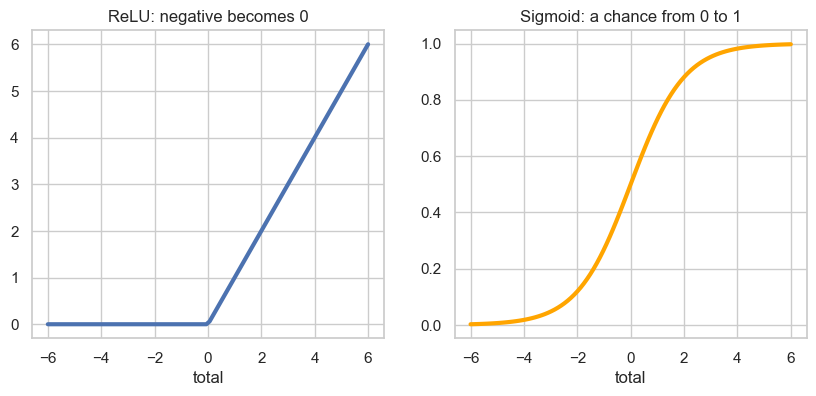

Ali's total was -2. Sigmoid gives a chance of going out: 0.12


In [11]:
totals = np.linspace(-6, 6, 100)

relu = np.maximum(0, totals)             # negative → 0
sigmoid = 1 / (1 + np.exp(-totals))      # squeeze into 0..1

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)                     # 2 charts side by side: this is chart 1
plt.plot(totals, relu, linewidth=3)
plt.title("ReLU: negative becomes 0")
plt.xlabel("total")

plt.subplot(1, 2, 2)                     # chart 2
plt.plot(totals, sigmoid, linewidth=3, color="orange")
plt.title("Sigmoid: a chance from 0 to 1")
plt.xlabel("total")
plt.show()

print("Ali's total was -2. Sigmoid gives a chance of going out:", round(1 / (1 + np.exp(2)), 2))

## CONCEPT: A network = many neurons in layers

One neuron can only make simple decisions. A **neural network** connects many neurons in **layers**:

```
   INPUT LAYER          HIDDEN LAYER            OUTPUT LAYER
   (the data)        (3 neurons, ReLU)        (1 neuron: the answer)

  study_hours ──┬────▶ ( neuron 1 ) ──┐
                ├────▶ ( neuron 2 ) ──┼────▶ ( output ) ──▶ predicted mark
  phone_hours ──┴────▶ ( neuron 3 ) ──┘
```

- Every input goes to **every** neuron in the next layer. Each arrow has its own **weight**.
- The **hidden layer** finds useful patterns by itself (like "studies a lot AND uses the phone little").
- The **forward pass** = the data flows from left to right, layer by layer, until the answer comes out.
- "**Deep** learning" just means **many** hidden layers.

### EXAMPLE: A forward pass, step by step

A student studies **3 hours** and uses the phone **2 hours**. We want the network to guess the Maths mark.

The network's weights are **random numbers for now**. We wrote them by hand only to show the calculation. The network has **not learned** anything yet. Learning comes in Hour 2.

**Hidden layer:** each of the 3 neurons does "inputs × weights + bias", then ReLU.

For example, in neuron 1: the study hours (3) are multiplied by the weight 0.5, the phone hours (2) by the weight −0.6, and the bias is 0.1.

| Neuron | Calculation | Total | After ReLU |
|--------|-------------|-------|------------|
| 1 | 3 × 0.5 + 2 × (−0.6) + 0.1 | **0.4** | 0.4 |
| 2 | 3 × (−1.0) + 2 × 0.4 + 0.2 | **−2.0** | **0** (negative → 0) |
| 3 | 3 × 0.8 + 2 × 0.2 + (−0.5) | **2.3** | 2.3 |

**Output neuron:** 0.4 × 2 + 0 × 1 + 2.3 × 3 + 1 = **8.7**

Now the same with NumPy. `@` does "multiply and add" for all neurons at once (the matrix multiplication from Class 13):

In [ ]:
x = np.array([3, 2])                      # study_hours, phone_hours

W1 = np.array([[ 0.5, -1.0, 0.8],         # weights from study_hours to neurons 1, 2, 3
               [-0.6,  0.4, 0.2]])        # weights from phone_hours to neurons 1, 2, 3
b1 = np.array([0.1, 0.2, -0.5])           # one bias for each hidden neuron

W2 = np.array([2, 1, 3])                  # weights from the 3 hidden neurons to the output
b2 = 1

hidden_total = x @ W1 + b1
print("Hidden totals:  ", hidden_total)

hidden = np.maximum(0, hidden_total)      # ReLU
print("After ReLU:     ", hidden)

output = hidden @ W2 + b2
print("Output (answer):", output)

The numbers match our table: 0.4, −2.0, 2.3 → ReLU → 0.4, 0, 2.3 → output **8.7**.

**But 8.7 is a bad guess for a Maths mark!** (A student who studies 3 hours gets about 55.) These weights were random numbers, so the guess is bad. The network has not **learned** anything yet.
**Learning = finding better weights.** That's Hour 2.

### ✏️ QUICK CHECK 2: Your own forward pass

A student studies **5 hours** and uses the phone **1 hour**. Use the same `W1, b1, W2, b2`, and calculate the output.

Which hidden neurons are 0 after ReLU this time?

Write your code in the cell below.

In [ ]:
# Write your code here

# Hour 2: How a Network Learns

## CONCEPT: Loss: one number for "how wrong"

- To learn, the network first needs to know **how wrong** it is.
- **Loss** = one number for the total error. Smaller loss = better guesses.
- For numbers (like marks), we use **MSE** from Class 20: square each error, then take the average.

Let's see the loss of two lines on our 100 students. (A line `maths = w × study + b` is the simplest network: **one neuron**, no activation.)

### EXAMPLE: A bad line and a good line

(`w` is the weight, `b` is the bias. The "good" numbers w = 9 and b = 28 come from `np.polyfit` in Class 16. A bad guess is `w = 0, b = 50`: it says 50 for every student.)

In [ ]:
x = students["study_hours"].values
y = students["maths"].values

def loss(w, b):
    prediction = w * x + b
    return ((prediction - y) ** 2).mean()      # MSE

print("Bad guess  (w=0, b=50): loss =", round(loss(0, 50)))
print("Good guess (w=9, b=28): loss =", round(loss(9, 28)))

plt.scatter(x, y, alpha=0.5)
plt.plot([0, 6], [50, 50], color="red", linewidth=3, label="bad: w=0, b=50")
plt.plot([0, 6], [28, 9 * 6 + 28], color="green", linewidth=3, label="good: w=9, b=28")
plt.title("Two lines, two losses")
plt.xlabel("Study hours")
plt.ylabel("Maths mark")
plt.legend()
plt.show()

The good line has a **much smaller loss**. So **learning = finding the `w` and `b` with the smallest loss.**

But a real network has **thousands or millions** of weights. We can't try every number. We need a smart way...

## CONCEPT: Gradient descent: walking down a hill in the fog

Imagine you are on a **hill**, in thick **fog**. You can't see the bottom. You want to reach the **lowest point** (the smallest loss).

What do you do?
1. Feel the ground under your feet: **which way goes down?**
2. Take a **small step** that way.
3. Repeat. Step by step, you reach the bottom.

```
 loss
  │ ●  ← start here (bad weights, big loss)
  │   ●
  │     ●       each step: feel the slope, step downhill
  │       ●
  │          ●  ●  ●   ← the bottom: the best weights (smallest loss)
  └──────────────────────── weight
```

- **"Which way goes down"** is called the **gradient**. The computer calculates it for every weight.
- The **step size** is the **learning rate**.
- This method is **gradient descent** ("descent" = going down). Every neural network learns this way.

## CONCEPT: Backpropagation: sending the blame back

- In a big network with many layers, the error comes out **at the end**.
- But every weight, in every layer, helped to make that error.
- **Backpropagation** sends the error **backwards** through the network, layer by layer. Each weight learns **how much it is to blame**, and which way it should change.
- **Like a cricket team after a loss:** the coach goes back through the match and tells each player what to change: the bowler, the fielder, the batsman.

You **don't** need to calculate this by hand. In the next class, PyTorch does it with **one line**: `loss.backward()`.

# Hour 3: Epochs, Batch Size, Learning Rate and Overfitting

## CONCEPT: Epochs and batch size

**Epoch** = one full round through **all** the training data.
- Like reading your whole textbook **once**. To really learn it, you read it many times → many epochs.
- Networks often train for 100 or 1,000 epochs.

**Batch size** = how many examples the network looks at **before it takes one step**.
- Batch size = all the data: one careful step per epoch. Slow, but smooth.
- Batch size = 32: look at 32 examples, take a step, look at the next 32, take a step...
- Like checking your answers after **every 32 questions**, not only at the end of the book. Many more steps → often faster learning.
- With small data (like ours), we use **all the data** in one batch. For big data (millions of photos), we **must** use batches, because all the data doesn't fit in memory.

## CONCEPT: The learning rate: the size of the step

| Learning rate | What happens | On the hill |
|---------------|--------------|-------------|
| **too small** | it learns, but **very slowly** | tiny baby steps, it takes forever |
| **just right** | it reaches the bottom quickly | good steps |
| **too big** | the loss **jumps around** or **explodes** to huge numbers | giant jumps over the bottom, to the other side, higher and higher |

Choosing the learning rate is mostly **trying a few values**: 0.1, 0.01, 0.001...

### EXAMPLE: Three learning rates on our students

In [ ]:
def train(x, y, learning_rate, epochs):
    w, b = 0.0, 0.0                    # start with a bad guess: a flat line at 0
    losses = []
    for epoch in range(epochs):
        prediction = w * x + b                     # 1. forward pass: guess
        error = prediction - y                     # 2. how wrong is each guess?
        losses.append((error ** 2).mean())         # 3. loss (MSE)
        w = w - learning_rate * (2 * error * x).mean()   # 4. step downhill for w
        b = b - learning_rate * (2 * error).mean()       #    and for b
    return w, b, losses

for lr in [0.001, 0.05, 0.12]:
    w, b, losses = train(x, y, learning_rate=lr, epochs=50)
    plt.plot(losses, label=f"learning rate {lr}")

plt.yscale("log")        # the loss can get huge, so we use a log scale here
plt.title("Loss during 50 epochs, for 3 learning rates")
plt.xlabel("Epoch")
plt.ylabel("Loss (log scale)")
plt.legend()
plt.show()

**How to read it:**
- **0.001 (too small):** the loss goes down, but slowly. After 50 epochs it is still high.
- **0.05 (good):** the loss drops fast, then stays low and flat. It found the bottom.
- **0.12 (too big):** the loss goes **up and up**. The steps jump over the bottom, every time a bit higher. It **explodes**.

(We use a **log scale** on the y-axis here, because the exploding loss gets so big that we can't see the other lines without it.)

## CONCEPT: Overfitting (again!)

You met overfitting with deep trees in Class 20. Networks overfit too, and they are very good at it, because they have so many weights.

- The network **memorises** the training data, including the random noise.
- **Train loss** keeps going down. **Test loss** goes down first, then goes **up**.

```
 loss
  │\                                 __/   TEST loss: goes UP again
  │ \                            __/       → memorising starts here!
  │  \___                    ___/
  │      \______      ______/
  │             \____/
  │  \
  │   \____
  │        \___________________________    TRAIN loss: keeps going down
  └──────────────────────────────────────── epochs
```

**How to stop overfitting:**
- **More data:** harder to memorise.
- **A smaller network:** fewer weights to memorise with.
- **Stop early:** stop training when the test (or validation) loss starts going up.

### EXAMPLE: Overfitting in a picture

In [ ]:
rng = np.random.default_rng(0)
x_small = np.linspace(0, 1, 10)
y_small = 2 * x_small + rng.normal(0, 0.2, 10)       # a straight pattern + some noise

simple = np.polyfit(x_small, y_small, 1)              # a straight line: 2 numbers
complex_ = np.polyfit(x_small, y_small, 9)            # a curvy line: 10 numbers (too many!)

x_line = np.linspace(0, 1, 200)
plt.scatter(x_small, y_small, s=60, color="black", label="10 training points")
plt.plot(x_line, np.polyval(simple, x_line), linewidth=3, label="simple: learned the pattern")
plt.plot(x_line, np.polyval(complex_, x_line), linewidth=2, label="complex: memorised every point")
plt.ylim(-1, 3.5)
plt.title("Overfitting: touching every point is NOT learning")
plt.legend()
plt.show()

The curvy line goes **exactly** through all 10 points: zero training error! But look **between** the points: it makes crazy jumps. For a **new** point, it would guess very badly.

The straight line misses every point a little, but it learned the **real pattern**. On new data, it will do much better.

# 🧑‍🏫 Class Problem: Train a neuron yourself

**The problem:** In Class 16, `np.polyfit` gave us the line `maths = 9.2 × study_hours + 28`, in one line of code. But **how** does a computer find it?

Today we find it **ourselves, with gradient descent**: start with a bad line, and improve it step by step. This is **exactly** how neural networks learn, just with one neuron.

We solve it **together**.

### Step 1: The data

In [ ]:
students = pd.read_csv("students_100.csv")
x = students["study_hours"].values
y = students["maths"].values
print(len(x), "students")

### Step 2: The training function

Read it line by line. It uses everything from today:

| Line | Idea |
|------|------|
| `w, b = 0.0, 0.0` | start with a bad guess |
| `prediction = w * x + b` | **forward pass**: the neuron guesses for all students |
| `error = prediction - y` | how wrong is each guess |
| `losses.append(...)` | the **loss** (MSE), saved so we can draw it |
| `w = w - learning_rate * ...` | **gradient descent**: a step downhill. `(2 * error * x).mean()` is the slope of the hill for `w` |
| `for epoch in range(epochs)` | repeat for many **epochs** |

(You don't need to know where `2 * error * x` comes from. It is the "which way is down" for this neuron. In the next class, PyTorch calculates it for us.)

In [ ]:
def train(x, y, learning_rate, epochs):
    w, b = 0.0, 0.0                    # start with a bad guess: a flat line at 0
    losses = []
    for epoch in range(epochs):
        prediction = w * x + b                     # 1. forward pass: guess
        error = prediction - y                     # 2. how wrong is each guess?
        losses.append((error ** 2).mean())         # 3. loss (MSE)
        w = w - learning_rate * (2 * error * x).mean()   # 4. step downhill for w
        b = b - learning_rate * (2 * error).mean()       #    and for b
    return w, b, losses

### Step 3: Train it, and watch it learn

In [ ]:
for epochs in [1, 10, 100, 500, 2000]:
    w, b, losses = train(x, y, learning_rate=0.05, epochs=epochs)
    print(f"after {epochs:4} epochs:  w = {w:5.2f}   b = {b:5.2f}   loss = {losses[-1]:7.1f}")

The loss gets smaller and smaller, and `w` and `b` move towards the best line.

### Step 4: Draw the loss curve

In [ ]:
w, b, losses = train(x, y, learning_rate=0.05, epochs=2000)

plt.plot(losses)
plt.title("Loss during training")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.ylim(0, 500)
plt.show()

### Step 5: Compare with `np.polyfit` from Class 16

In [ ]:
slope, start = np.polyfit(x, y, 1)
print("Gradient descent: w =", round(w, 2), "  b =", round(b, 2))
print("np.polyfit:       w =", round(slope, 2), "  b =", round(start, 2))

**The same line!** Our neuron learned `maths = 9.19 × study_hours + 28.09`, by itself, only by taking small steps downhill.

**What we learned:**
> A neural network does not "think". It starts with random weights, measures how wrong it is (the loss), and changes every weight a little bit downhill. Thousands of times. That's all "learning" is. ChatGPT learned the same way, with billions of weights instead of 2.

# 🏠 Home Problem: Teach a neuron about car prices

Old cars are cheaper. A neuron can learn **how much cheaper** with each year. **Same steps as the Class Problem**, on new data.

The data is in `cars.csv`. Use only 2 columns: `car_age` (x) and `price_lakh` (y).

1. Load `cars.csv`. Make `x = cars["car_age"].values` and `y = cars["price_lakh"].values`.
2. Copy the `train` function from the Class Problem.
3. Train with `learning_rate=0.01`, for `1, 10, 100, 1000, 3000` epochs. Print `w`, `b` and the loss each time.
4. Draw the loss curve for 3000 epochs.
5. Compare with `np.polyfit(x, y, 1)`. Are they the same?
6. **Explain `w` in words:** each year older, the price changes by how much?
7. **Experiment:** train with `learning_rate=0.02` for 20 epochs. Print the loss. What happened, and why?

**Bring to the next class:** your notebook, your answer to question 6, and your explanation for question 7.

In [ ]:
# Write your code here

# Home Practice: Interview-Style Questions

1. What does one neuron do? Explain with an everyday example.
2. What are weights and bias?
3. What does the ReLU activation do? What does sigmoid do?
4. What is a forward pass?
5. What is a loss? Why do we need it?
6. Explain gradient descent with the "hill in the fog" story.
7. What happens if the learning rate is too big? Too small?
8. What is an epoch? What is batch size?
9. What is overfitting? Give 2 ways to stop it.

# Key Takeaways

- A **neuron**: inputs × **weights**, add them up, add the **bias**, then an **activation** decides the output.
- **ReLU** = negative becomes 0. **Sigmoid** = a chance from 0 to 1.
- A **network** = neurons in **layers**. The **forward pass** goes from the inputs to the answer.
- **Loss** = how wrong the network is. **Learning = making the loss smaller.**
- **Gradient descent** = small steps downhill. The **learning rate** = the step size.
- **Backpropagation** sends the error back, so every weight knows how to change.
- **Epoch** = one round through all the data. **Batch** = examples per step.
- **Overfitting** = memorising. Watch the test loss.

**Next class:** PyTorch: build and train a real neural network, with all of this done for us.